# Task 3: reproduction notebook

This notebook imports the modules in `src/` and reproduces every final table and figure of Task 3, top to bottom.

**Recomputed here:** the data pipeline and its checks, the harness controls, the walk-forward of the four frozen finalists from 1990 to 2013 (about 20 minutes), their development and test scores, and the two post-hoc analyses. Each recomputed table is compared with the saved file and must match.

**Loaded from saved files, not recomputed:** the 62 development experiments of Phase 2 (about two hours; run `python src/task3_phase2.py` and `python src/task3_phase2b.py` stage by stage to redo them). Their rows come from `results/experiment_log.csv`.

Nothing in this notebook writes to the experiment log. The test-period numbers below repeat the single frozen evaluation with the same predictions; they are a reproduction, not a new evaluation.

In [17]:
import json
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":      # the modules expect the repository root
    os.chdir("..")
sys.path.insert(0, "src")

import numpy as np
import pandas as pd

from task3_data import build_targets
from task3_eval import evaluate, sharpe
from task3_phase3 import compute_predictions, load_config
from task3_posthoc import hedge_stats
import task3_phase2_report as report2
import task3_phase3_report as report3

%matplotlib inline
pd.set_option("display.width", 200, "display.max_rows", 100, "display.max_colwidth", 70)
print("working directory:", os.getcwd())

working directory: /Users/louissalanon/ecse551-assignment1


## 1. Data pipeline and its checks (Phase 0)

In [18]:
ret, ind, meta, sig, vadj, vadj_c, Y, mem = build_targets("data")

member_vadj = vadj.where(mem).stack().dropna()          # vol-adjusted returns on member cells
members_per_day = ind.sum(axis=1)
checks = pd.DataFrame([
    ["securities remaining", 1314, ret.shape[1]],
    ["trading days", 8577, ret.shape[0]],
    ["mean members per day", 499.79, round(members_per_day.mean(), 2)],
    ["min members per day", 489, int(members_per_day.min())],
    ["member cells with NaN return", 0, int((ret.isna() & (ind == 1)).sum().sum())],
    ["non-member cells with a return", 2190592, int((ret.notna() & (ind == 0)).sum().sum())],
    ["vol-adjusted returns on member cells", 4227347, len(member_vadj)],
    ["their standard deviation", 1.0574, round(member_vadj.std(), 4)],
    ["their excess kurtosis", 22.75, round(member_vadj.kurt(), 2)],
    ["share with absolute value above 5", 0.00201, round((member_vadj.abs() > 5).mean(), 5)],
], columns=["check", "expected", "actual"])
checks

,check,expected,actual
0,securities remaining,1.314000e+03,1.314000e+03
1,trading days,8.577000e+03,8.577000e+03
2,mean members per day,4.997900e+02,4.997900e+02
3,min members per day,4.890000e+02,4.890000e+02
4,member cells with NaN return,0.000000e+00,0.000000e+00
5,non-member cells with a return,2.190592e+06,2.190592e+06
6,vol-adjusted returns on member cells,4.227347e+06,4.227347e+06
7,their standard deviation,1.057400e+00,1.057400e+00
8,their excess kurtosis,2.275000e+01,2.275000e+01
9,share with absolute value above 5,2.010000e-03,2.010000e-03


## 2. Harness controls (Phase 0)

Three controls with no model, on 2011-2013: perfect foresight must give an absurd Sharpe, random predictions a Sharpe near zero, and an always-long portfolio a market correlation near one. Then the 5-day reversal baseline on 1985-2010.

In [19]:
rng = np.random.default_rng(42)
P_cheat = Y.copy()                                                           # perfect foresight
P_rand = pd.DataFrame(rng.standard_normal(vadj.shape), vadj.index, vadj.columns)
P_long = pd.DataFrame(1.0, vadj.index, vadj.columns)
P_rev = -vadj_c.rolling(5, min_periods=3).mean()                             # row t uses days t-4..t

_, _, cheat = evaluate(P_cheat, Y, mem, "2011-01-01", "2013-12-31", label="perfect foresight", plot=False)
_, _, rand = evaluate(P_rand, Y, mem, "2011-01-01", "2013-12-31", label="random", plot=False)
_, _, long = evaluate(P_long, Y, mem, "2011-01-01", "2013-12-31", label="always long", plot=False)
_, _, rev = evaluate(P_rev, Y, mem, "1985-01-01", "2010-12-31", demean=True, label="5-day reversal 1985-2010", plot=False)

pd.DataFrame([
    ["perfect foresight: Sharpe", "> 10", round(cheat["Sharpe"], 3)],
    ["random N(0,1), seed 42: Sharpe", "|.| < 1.5", round(rand["Sharpe"], 3)],
    ["always long: market correlation", "> 0.9", round(long["corr w/ market"], 3)],
    ["5-day reversal 1985-2010: Sharpe", "report only", round(rev["Sharpe"], 3)],
], columns=["control", "requirement", "actual"])

/Users/louissalanon/ecse551-assignment1/src/task3_eval.py:58: RuntimeWarning: divide by zero encountered in scalar divide
  "IC t-stat": ic.mean() / ic.std() * np.sqrt(len(ic)),


===== perfect foresight [2011-01-01 -> 2013-12-31] =====
                Sharpe: 16.598
               mean IC: 1.000
             IC t-stat: inf
 holding period (days): 0.684
        corr w/ market: -0.188
         min preds/day: 496
Sharpe by year: {2011: 13.05, 2012: 22.18, 2013: 23.74}
===== random [2011-01-01 -> 2013-12-31] =====
                Sharpe: 0.314
               mean IC: 0.002
             IC t-stat: 1.296
 holding period (days): 0.708
        corr w/ market: 0.056
         min preds/day: 496
Sharpe by year: {2011: 0.09, 2012: -0.26, 2013: 1.16}
===== always long [2011-01-01 -> 2013-12-31] =====
                Sharpe: 1.101
               mean IC: nan
             IC t-stat: nan
 holding period (days): nan
        corr w/ market: 1.000
         min preds/day: 496
Sharpe by year: {2011: 0.06, 2012: 1.22, 2013: 2.47}
===== 5-day reversal 1985-2010 [1985-01-01 -> 2010-12-31] =====
                Sharpe: 2.327
               mean IC: 0.026
             IC t-stat: 18.493


,control,requirement,actual
0,perfect foresight: Sharpe,> 10,16.598
1,"random N(0,1), seed 42: Sharpe",|.| < 1.5,0.314
2,always long: market correlation,> 0.9,1.000
3,5-day reversal 1985-2010: Sharpe,report only,2.327


## 3. Features (Phase 1)

Loaded from `results/feature_table.csv` (statistics up to 2010-12-31).

In [20]:
features = pd.read_csv("results/feature_table.csv")
features[["name", "formula", "lookback_days", "first_available", "mean_coverage", "fill_fraction"]]

,name,formula,lookback_days,first_available,mean_coverage,fill_fraction
0,rev_1,rank among members of: vadj_c[t],1,1980-05-23,0.9978,0.0022
1,rev_1_hl5,EWMA over time (half-life 5 days) of ranked rev_1,1 + EWMA (half-life 5),1980-05-23,0.9978,0.0022
2,rev_1_hl10,EWMA over time (half-life 10 days) of ranked rev_1,1 + EWMA (half-life 10),1980-05-23,0.9978,0.0022
3,rev_5,rank among members of: mean of vadj_c over t-4..t (at least 3 values),5,1980-05-28,0.9978,0.0022
4,rev_5_hl5,EWMA over time (half-life 5 days) of ranked rev_5,5 + EWMA (half-life 5),1980-05-28,0.9978,0.0022
5,rev_5_hl10,EWMA over time (half-life 10 days) of ranked rev_5,5 + EWMA (half-life 10),1980-05-28,0.9978,0.0022
6,rev_21,rank among members of: mean of vadj_c over t-20..t (at least 15 va...,21,1980-06-13,0.9975,0.0025
7,rev_21_hl5,EWMA over time (half-life 5 days) of ranked rev_21,21 + EWMA (half-life 5),1980-06-13,0.9975,0.0025
8,rev_21_hl10,EWMA over time (half-life 10 days) of ranked rev_21,21 + EWMA (half-life 10),1980-06-13,0.9975,0.0025
9,mom_12_1,rank among members of: sum of vadj_c over t-251..t-21 (all 231 val...,252,1981-05-22,0.9869,0.0131


## 4. Development experiments (Phase 2), loaded from the log

Prediction dates 1990-2010, demeaned predictions. Controls and diagnostics are marked in the `model` column and were never eligible for selection.

In [21]:
dev = report2.load_results()
print(len(dev), "development rows")
columns = ["exp_id", "name", "model", "dev_sharpe"] + report2.WINDOW_COLS + ["holding_period", "mean_ic", "min_preds_per_day"]
dev[dev.start == "1990-01-01"][columns].round(3)

62 development rows


,exp_id,name,model,dev_sharpe,sharpe_1990_1994,sharpe_1995_1999,sharpe_2000_2004,sharpe_2005_2010,holding_period,mean_ic,min_preds_per_day
32,E037,control_positive_leaky_features,control_positive,68.282,105.160,103.548,64.092,60.650,0.748,0.995,493.0
53,E058,ext_rf_3y_d12_l200,rf,5.784,10.186,6.491,4.139,2.697,1.088,0.033,493.0
52,E057,ext_rf_3y_d10_l200,rf,5.682,9.960,6.406,4.126,2.558,1.112,0.033,493.0
24,E029,rf_3y_d8_l200,rf,5.500,9.523,6.247,3.950,2.552,1.143,0.033,493.0
54,E059,ext_mlp_3y_h32_cap60,mlp,5.394,9.198,6.334,3.857,2.687,1.270,0.034,493.0
55,E060,ext_mlp_3y_h64,mlp,5.387,8.942,6.785,3.713,2.613,1.292,0.034,493.0
25,E030,rf_3y_d8_l1000,rf,5.188,9.207,5.771,3.706,2.409,1.210,0.033,493.0
28,E033,mlp_3y_h32_a0.0001,mlp,5.159,8.555,6.081,3.735,2.557,1.289,0.033,493.0
29,E034,mlp_3y_h32_a0.01,mlp,5.144,8.609,6.050,3.656,2.570,1.296,0.033,493.0
22,E027,rf_3y_d6_l200,rf,5.142,8.952,5.867,3.737,2.265,1.187,0.032,493.0


In [22]:
# Sentiment study: judged on 2010 only (one year, standard error of the Sharpe about 1.0)
dev[dev.start == "2010-01-01"][["exp_id", "name", "features", "dev_sharpe", "mean_ic", "holding_period"]].round(3)

,exp_id,name,features,dev_sharpe,mean_ic,holding_period
38,E043,sent_rf_return_18+sentiment_13,return_18+sentiment_13,1.321,0.004,2.427
33,E038,sent_lasso_return_18_a5,return_18,0.425,0.003,2.101
36,E041,sent_lasso_return_18+sentiment_13_a2,return_18+sentiment_13,0.368,0.003,2.296
35,E040,sent_lasso_return_18_a2,return_18,0.367,0.003,2.313
34,E039,sent_lasso_return_18+sentiment_13_a5,return_18+sentiment_13,0.315,0.003,1.915
37,E042,sent_lasso_sentiment_13_a5,sentiment_13,-0.904,-0.002,3.538


In [23]:
# The two leakage controls next to the Lasso they are built on
dev[dev.exp_id.isin(["E012", "E036", "E037"])][["exp_id", "name", "dev_sharpe", "mean_ic"] + report2.WINDOW_COLS].round(3)

,exp_id,name,dev_sharpe,mean_ic,sharpe_1990_1994,sharpe_1995_1999,sharpe_2000_2004,sharpe_2005_2010
32,E037,control_positive_leaky_features,68.282,0.995,105.160,103.548,64.092,60.650
7,E012,lasso_3y_a5,4.064,0.030,7.484,4.768,2.601,1.808
31,E036,control_negative_permuted_target,-0.024,0.003,1.218,-0.047,0.060,-0.667


### Development figures

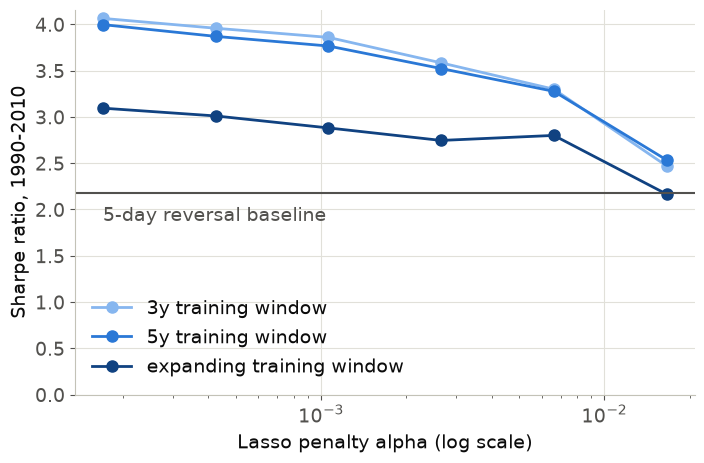

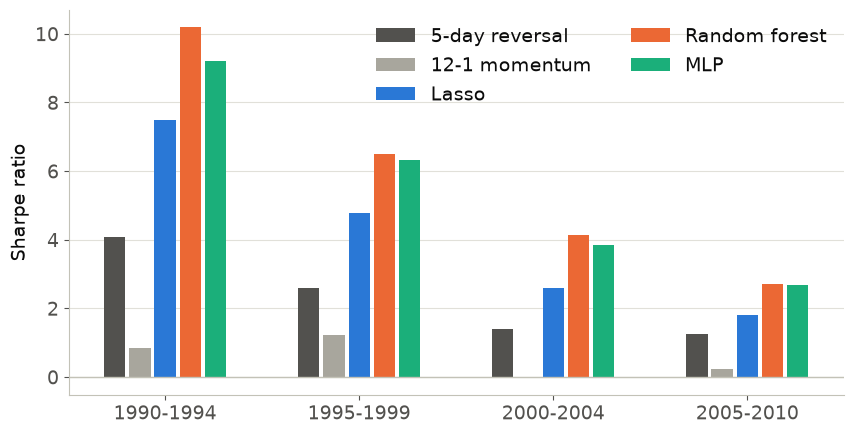

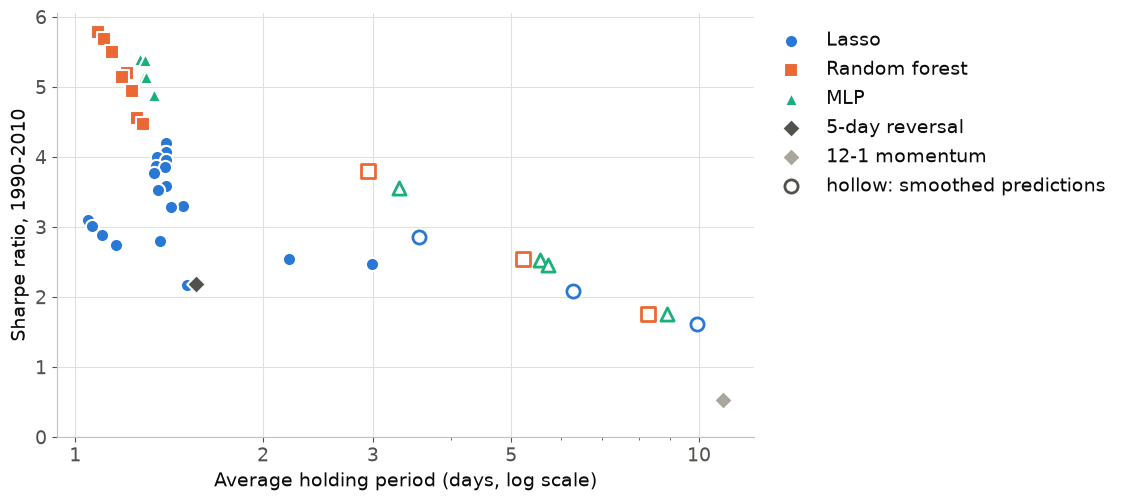

In [24]:
report2.fig_lasso_grid(dev)
report2.fig_sharpe_by_window(dev)
report2.fig_sharpe_vs_holding(dev)

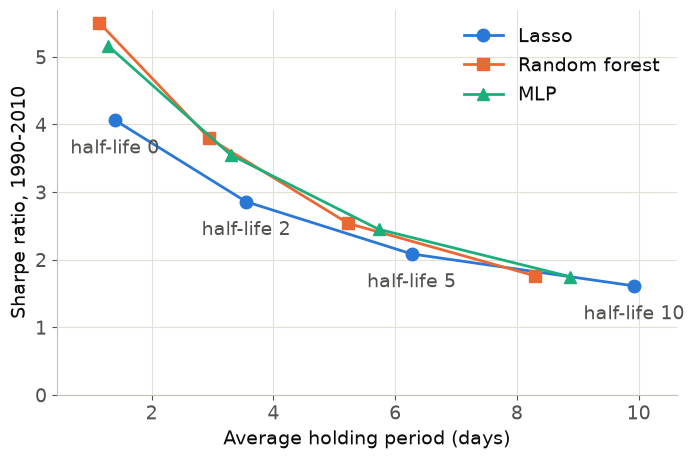

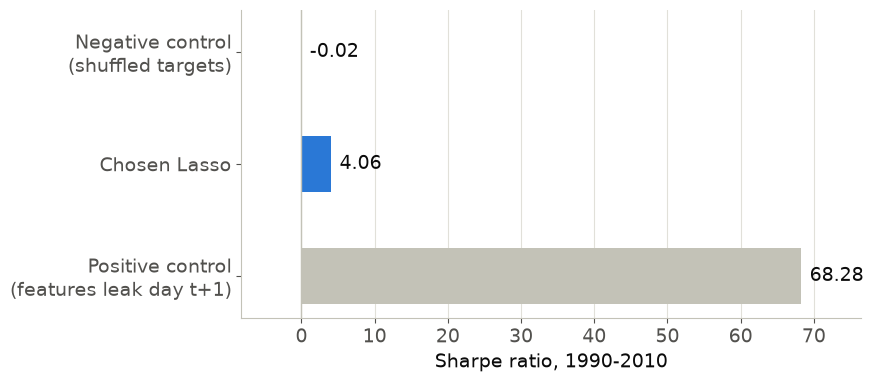

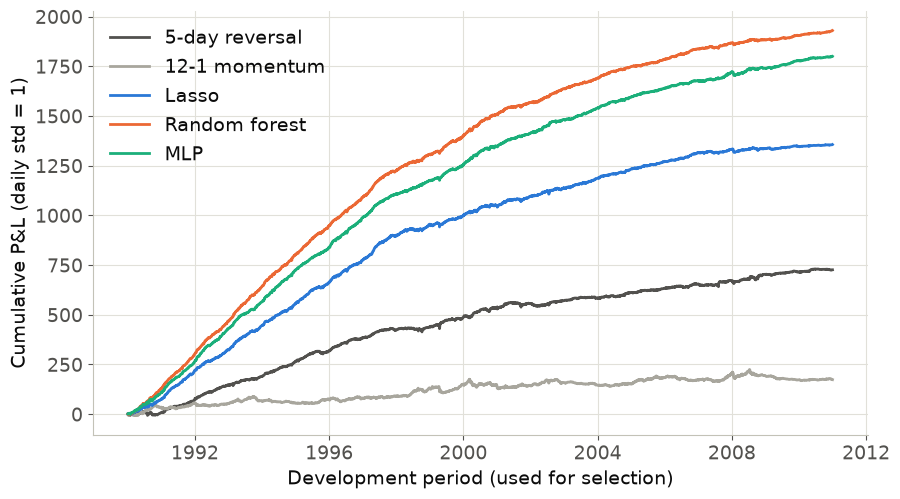

In [25]:
report2.fig_smoothing_tradeoff(dev)
report2.fig_controls(dev)
report2.fig_cumulative_pnl(dev)

## 5. The frozen finalists

Read from `results/final_configs.json`, committed before any test-period run.

In [26]:
config = load_config()
frozen = pd.DataFrame(config["finalists"] + config["baselines"])
frozen["spec"] = frozen["spec"].astype(str)
print("development period:", config["development_period"], "| test period:", config["test_period"])
frozen[["name", "source_exp_id", "spec", "rule", "refit_every", "train_window_days", "subsample",
        "pred_smoothing_halflife", "dev_sharpe_1990_2010"]]

development period: ['1990-01-01', '2010-12-31'] | test period: ['2011-01-01', '2013-12-31']


,name,source_exp_id,spec,rule,refit_every,train_window_days,subsample,pred_smoothing_halflife,dev_sharpe_1990_2010
0,lasso,E012,"{'model': 'lasso', 'alpha': 0.0001697043268440639}",NaN,63.0,756.0,NaN,0.0,4.0640
1,rf,E058,"{'model': 'rf', 'max_depth': 12, 'min_samples_leaf': 200}",NaN,252.0,756.0,200000.0,0.0,5.7837
2,mlp,E059,"{'model': 'mlp', 'hidden': 32, 'alpha': 0.0001, 'max_epochs': 60}",NaN,252.0,756.0,NaN,0.0,5.3944
3,mlp_slow,E066,"{'model': 'mlp', 'hidden': 32, 'alpha': 0.0001, 'max_epochs': 60}",NaN,252.0,756.0,NaN,5.0,2.5310
4,baseline_rev_5,E005,NaN,"-vadj_c.rolling(5, min_periods=3).mean()",NaN,NaN,NaN,NaN,2.1757
5,baseline_mom_12_1,E006,NaN,"vadj_c.rolling(231, min_periods=231).sum().shift(21)",NaN,NaN,NaN,NaN,0.5196


## 6. Walk-forward of the finalists, 1990-2013 (recomputed, about 20 minutes)

At each refit date the model is fitted on the 756 trading days before it and predicts until the next refit. Every fit asserts that no training row is dated on or after the refit date.

In [27]:
tables, records = compute_predictions(config, vadj_c, sig, mem, meta)
names = [entry["name"] for entry in config["finalists"] + config["baselines"]]
{name: tables[name].shape for name in names}

walk-forward: lasso {'model': 'lasso', 'alpha': 0.0001697043268440639}
walk-forward: rf {'model': 'rf', 'max_depth': 12, 'min_samples_leaf': 200}
walk-forward: mlp {'model': 'mlp', 'hidden': 32, 'alpha': 0.0001, 'max_epochs': 60}


{'lasso': (6049, 1314),
 'rf': (6049, 1314),
 'mlp': (6049, 1314),
 'mlp_slow': (6049, 1314),
 'baseline_rev_5': (6049, 1314),
 'baseline_mom_12_1': (6049, 1314)}

### Development period: the recomputed Sharpe must equal the frozen value

In [16]:
dev_start, dev_end = config["development_period"]
dev_pnl, rows = {}, []
for entry in config["finalists"] + config["baselines"]:
    name = entry["name"]
    pnl, ic, out = evaluate(tables[name], Y, mem, dev_start, dev_end, demean=True, label=name + " (development)", plot=False)
    dev_pnl[name] = pnl
    rows.append({"name": name, "recomputed": out["Sharpe"], "frozen": entry["dev_sharpe_1990_2010"],
                 "holding_period": out["holding period (days)"],
                 "1990-1994": sharpe(pnl.loc["1990":"1994"]), "1995-1999": sharpe(pnl.loc["1995":"1999"]),
                 "2000-2004": sharpe(pnl.loc["2000":"2004"]), "2005-2010": sharpe(pnl.loc["2005":"2010"])})
dev_table = pd.DataFrame(rows).set_index("name")
assert (dev_table.recomputed - dev_table.frozen).abs().max() < 1e-3
dev_table.round(3)

===== lasso (development) [1990-01-01 -> 2010-12-31] =====
                Sharpe: 4.064
               mean IC: 0.030
             IC t-stat: 19.240
 holding period (days): 1.3946932554244995
        corr w/ market: 0.289
         min preds/day: 493
Sharpe by year: {1990: 5.07, 1991: 10.13, 1992: 7.44, 1993: 7.72, 1994: 7.29, 1995: 6.22, 1996: 6.17, 1997: 6.88, 1998: 2.83, 1999: 2.32, 2000: 2.0, 2001: 2.37, 2002: 2.28, 2003: 3.66, 2004: 4.3, 2005: 3.28, 2006: 4.29, 2007: 1.1, 2008: 0.35, 2009: 1.32, 2010: 1.66}
===== rf (development) [1990-01-01 -> 2010-12-31] =====
                Sharpe: 5.784
               mean IC: 0.033
             IC t-stat: 27.005
 holding period (days): 1.0877331495285034
        corr w/ market: 0.243
         min preds/day: 493
Sharpe by year: {1990: 7.17, 1991: 14.45, 1992: 11.52, 1993: 11.03, 1994: 9.04, 1995: 8.44, 1996: 8.61, 1997: 7.84, 1998: 4.01, 1999: 4.62, 2000: 4.61, 2001: 3.45, 2002: 4.33, 2003: 4.22, 2004: 4.74, 2005: 3.14, 2006: 5.17, 2007: 2.13

,recomputed,frozen,holding_period,1990-1994,1995-1999,2000-2004,2005-2010
name,,,,,,,
lasso,4.064,4.064,1.395,7.484,4.768,2.601,1.808
rf,5.784,5.784,1.088,10.186,6.491,4.139,2.697
mlp,5.394,5.394,1.270,9.198,6.334,3.857,2.687
mlp_slow,2.531,2.531,5.562,4.019,3.458,1.709,1.429
baseline_rev_5,2.176,2.176,1.562,4.087,2.591,1.395,1.253
baseline_mom_12_1,0.520,0.520,10.907,0.850,1.223,-0.012,0.234


## 7. Test period 2011-2013

This repeats the single frozen test evaluation with the predictions recomputed above and checks that it gives the saved numbers.

In [17]:
test_start, test_end = config["test_period"]
saved = pd.read_csv("results/test_results.csv").set_index("name")
test_pnl, rows = {}, []
for name in names:
    pnl, ic, out = evaluate(tables[name], Y, mem, test_start, test_end, demean=True, label="TEST " + name, plot=False)
    test_pnl[name] = pnl
    rows.append({"name": name, "test_sharpe": out["Sharpe"], "saved": saved.test_sharpe[name],
                 "2011": sharpe(pnl.loc["2011"]), "2012": sharpe(pnl.loc["2012"]), "2013": sharpe(pnl.loc["2013"]),
                 "mean_ic": out["mean IC"], "ic_tstat": out["IC t-stat"],
                 "holding_period": out["holding period (days)"], "corr_market": out["corr w/ market"],
                 "expected_low": saved.expected_low[name], "expected_high": saved.expected_high[name]})
test_table = pd.DataFrame(rows).set_index("name")
assert (test_table.test_sharpe - test_table.saved).abs().max() < 1e-3
test_table.round(3)

===== TEST lasso [2011-01-01 -> 2013-12-31] =====
                Sharpe: 1.067
               mean IC: 0.014
             IC t-stat: 2.674
 holding period (days): 1.484063982963562
        corr w/ market: 0.382
         min preds/day: 496
Sharpe by year: {2011: 1.31, 2012: 0.64, 2013: 1.22}
===== TEST rf [2011-01-01 -> 2013-12-31] =====
                Sharpe: 3.650
               mean IC: 0.018
             IC t-stat: 5.553
 holding period (days): 0.9443798661231995
        corr w/ market: 0.394
         min preds/day: 496
Sharpe by year: {2011: 3.2, 2012: 3.69, 2013: 4.15}
===== TEST mlp [2011-01-01 -> 2013-12-31] =====
                Sharpe: 3.009
               mean IC: 0.018
             IC t-stat: 5.654
 holding period (days): 1.043226957321167
        corr w/ market: 0.309
         min preds/day: 496
Sharpe by year: {2011: 2.02, 2012: 3.22, 2013: 4.09}
===== TEST mlp_slow [2011-01-01 -> 2013-12-31] =====
                Sharpe: 1.399
               mean IC: 0.007
             

,test_sharpe,saved,2011,2012,2013,mean_ic,ic_tstat,holding_period,corr_market,expected_low,expected_high
name,,,,,,,,,,,
lasso,1.067,1.067,1.314,0.641,1.221,0.014,2.674,1.484,0.382,0.60,2.4
rf,3.650,3.650,3.201,3.688,4.151,0.018,5.553,0.944,0.394,1.20,3.3
mlp,3.009,3.009,2.019,3.222,4.090,0.018,5.654,1.043,0.309,1.20,3.3
mlp_slow,1.399,1.399,0.107,1.541,2.854,0.007,1.839,4.510,0.401,0.35,2.0
baseline_rev_5,0.725,0.725,1.555,-0.320,0.849,0.008,1.867,1.612,0.154,0.20,1.8
baseline_mom_12_1,0.786,0.786,0.749,0.483,1.153,0.019,3.208,11.436,0.120,-0.40,0.8


## 8. Post-hoc analyses of the frozen test predictions

Both were run after the test evaluation, at the group's request. They describe the test result; they are not additional out-of-sample tests.

### 8.1 Delayed execution: every prediction used one day late

In [18]:
saved_delay = pd.read_csv("results/posthoc_test_delay.csv").set_index("name")
rows = []
for name in names:
    delayed = tables[name].shift(1)                      # row t holds the prediction made on day t-1
    pnl, ic, out = evaluate(delayed, Y, mem, test_start, test_end, demean=True, label="one day late: " + name, plot=False)
    rows.append({"name": name, "on_time": test_table.test_sharpe[name], "one_day_late": out["Sharpe"],
                 "saved": saved_delay.test_sharpe_one_day_late[name],
                 "share_kept": out["Sharpe"] / test_table.test_sharpe[name],
                 "2011": sharpe(pnl.loc["2011"]), "2012": sharpe(pnl.loc["2012"]), "2013": sharpe(pnl.loc["2013"])})
delay_table = pd.DataFrame(rows).set_index("name")
assert (delay_table.one_day_late - delay_table.saved).abs().max() < 1e-3
delay_table.round(3)

===== one day late: lasso [2011-01-01 -> 2013-12-31] =====
                Sharpe: 0.724
               mean IC: 0.008
             IC t-stat: 1.557
 holding period (days): 1.4825270175933838
        corr w/ market: 0.376
         min preds/day: 495
Sharpe by year: {2011: 0.77, 2012: 0.01, 2013: 1.34}
===== one day late: rf [2011-01-01 -> 2013-12-31] =====
                Sharpe: 1.236
               mean IC: 0.005
             IC t-stat: 1.445
 holding period (days): 0.9446278810501099
        corr w/ market: 0.405
         min preds/day: 495
Sharpe by year: {2011: 0.73, 2012: 0.04, 2013: 2.99}
===== one day late: mlp [2011-01-01 -> 2013-12-31] =====
                Sharpe: 1.024
               mean IC: 0.005
             IC t-stat: 1.501
 holding period (days): 1.0427426099777222
        corr w/ market: 0.374
         min preds/day: 495
Sharpe by year: {2011: 0.26, 2012: 0.49, 2013: 2.77}
===== one day late: mlp_slow [2011-01-01 -> 2013-12-31] =====
                Sharpe: 0.931
    

,on_time,one_day_late,saved,share_kept,2011,2012,2013
name,,,,,,,
lasso,1.067,0.724,0.724,0.678,0.771,0.013,1.342
rf,3.650,1.236,1.236,0.338,0.729,0.039,2.991
mlp,3.009,1.024,1.024,0.340,0.262,0.485,2.768
mlp_slow,1.399,0.931,0.931,0.665,-0.358,1.112,2.373
baseline_rev_5,0.725,0.694,0.694,0.957,1.119,-0.636,1.628
baseline_mom_12_1,0.786,0.821,0.821,1.044,0.738,0.514,1.231


### 8.2 Market-hedged Sharpe

Each daily P&L is regressed on the equal-weight market return (the mean over members of the next-day vol-adjusted return, as in `evaluate`). The hedged P&L is the P&L minus beta times the market.

In [19]:
saved_hedge = pd.read_csv("results/posthoc_test_hedge.csv").set_index("name")
market = Y.where(mem).loc[test_start:test_end].mean(axis=1)       # same-day mean over members
rows = []
for name in names:
    stats, hedged = hedge_stats(test_pnl[name], market.reindex(test_pnl[name].index))
    stats["name"], stats["saved_hedged"] = name, saved_hedge.test_sharpe_hedged[name]
    rows.append(stats)
hedge_table = pd.DataFrame(rows).set_index("name")
assert (hedge_table.test_sharpe_hedged - hedge_table.saved_hedged).abs().max() < 1e-3
hedge_table[["corr_market", "beta", "beta_tstat", "r_squared", "test_sharpe_unhedged", "test_sharpe_hedged", "market_sharpe"]].round(3)

,corr_market,beta,beta_tstat,r_squared,test_sharpe_unhedged,test_sharpe_hedged,market_sharpe
name,,,,,,,
lasso,0.382,0.591,11.321,0.146,1.067,0.699,1.102
rf,0.394,0.611,11.742,0.155,3.650,3.499,1.102
mlp,0.309,0.545,8.919,0.096,3.009,2.805,1.102
mlp_slow,0.401,0.453,12.004,0.161,1.399,1.044,1.102
baseline_rev_5,0.154,3.734,4.271,0.024,0.725,0.562,1.102
baseline_mom_12_1,0.120,129.722,3.313,0.014,0.786,0.659,1.102


## 9. Test-period figures

Drawn from the saved files, which the cells above have just shown to equal the recomputed values.

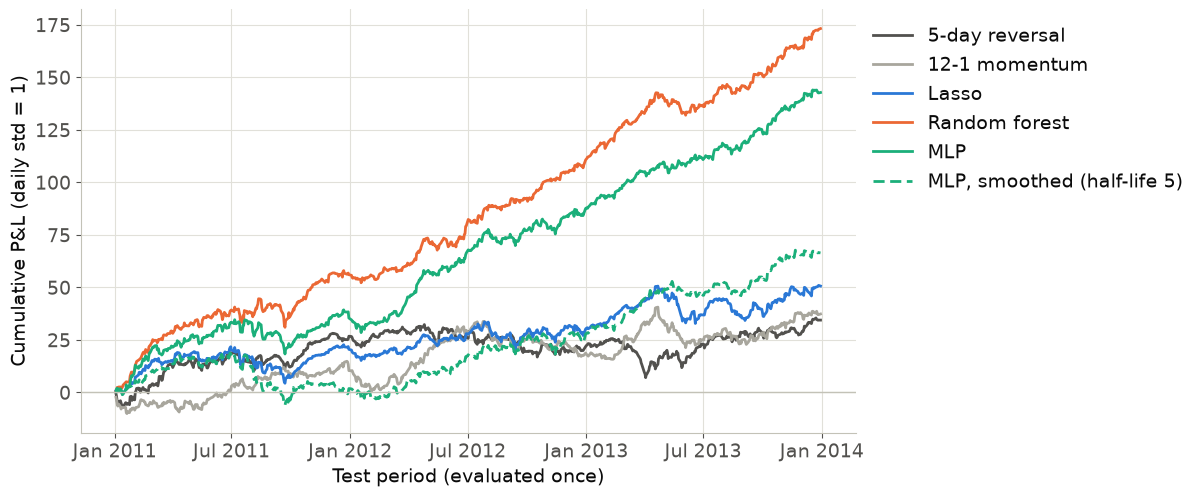

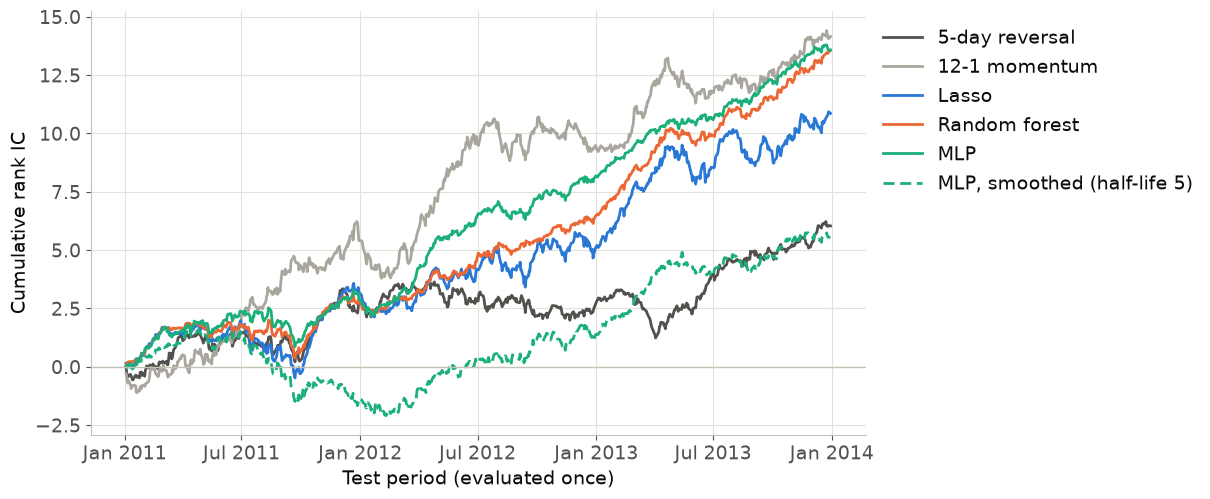

In [20]:
report3.fig_test_cumulative("test_pnl.csv", "phase3_test_cumulative_pnl.pdf", "Cumulative P&L (daily std = 1)", scale=True)
report3.fig_test_cumulative("test_ic.csv", "phase3_test_cumulative_ic.pdf", "Cumulative rank IC", scale=False)

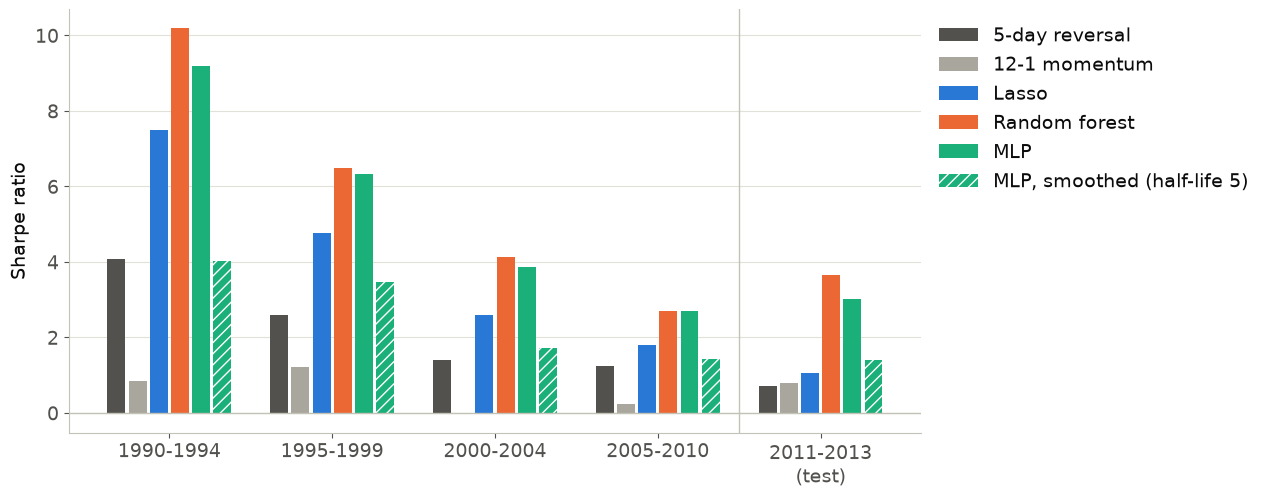

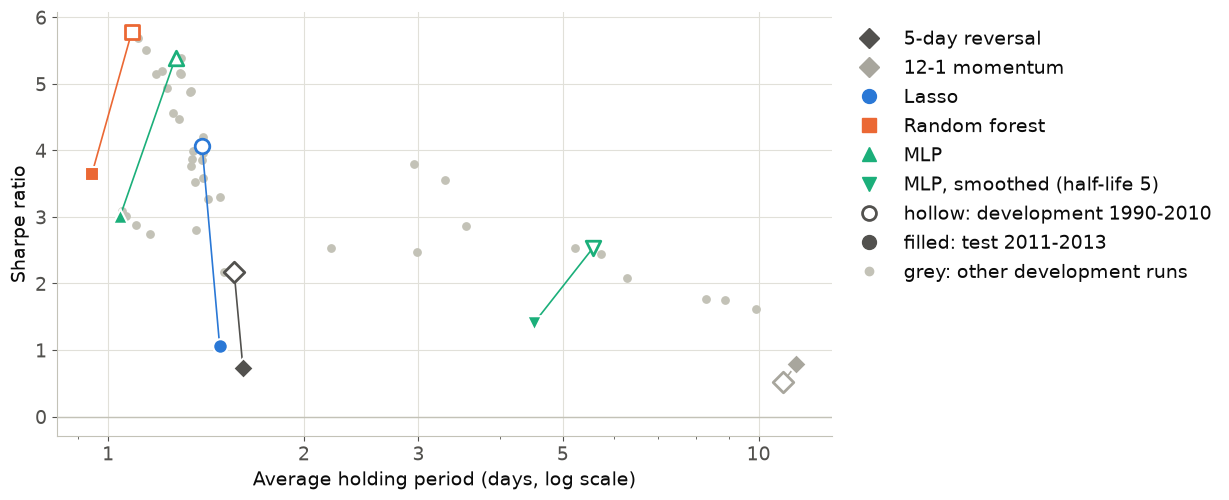

In [21]:
saved_test = pd.read_csv("results/test_results.csv").set_index("name")
report3.fig_sharpe_by_window(saved_test)
report3.fig_sharpe_vs_holding(saved_test)

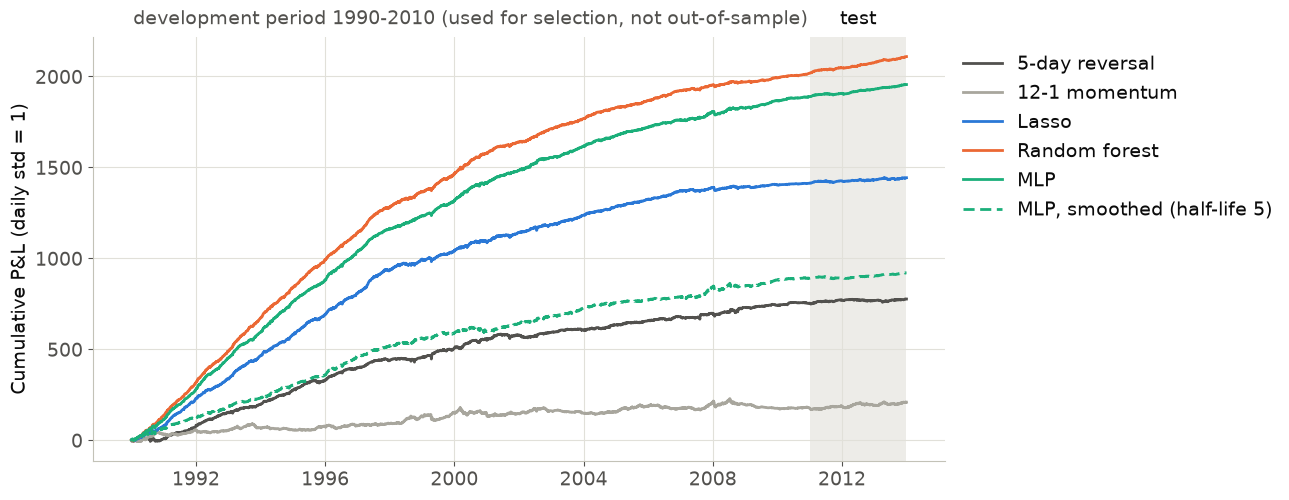

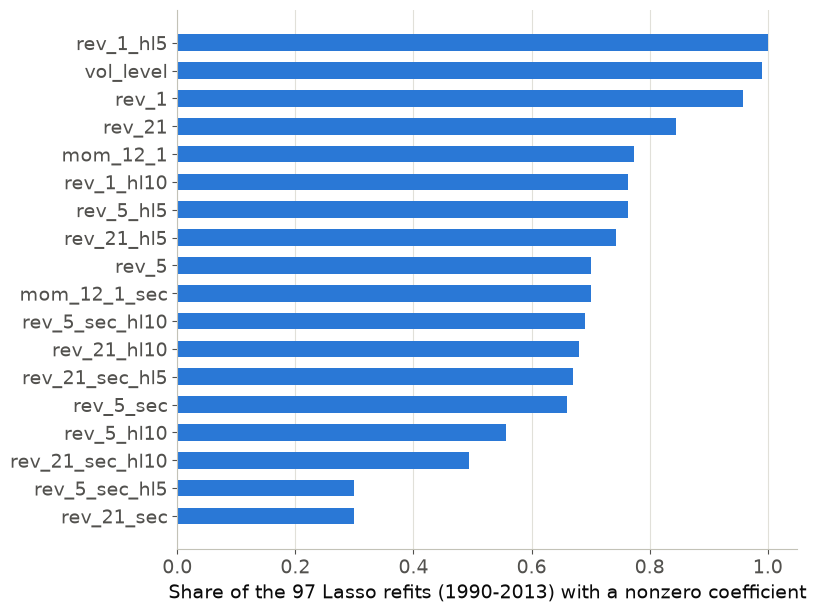

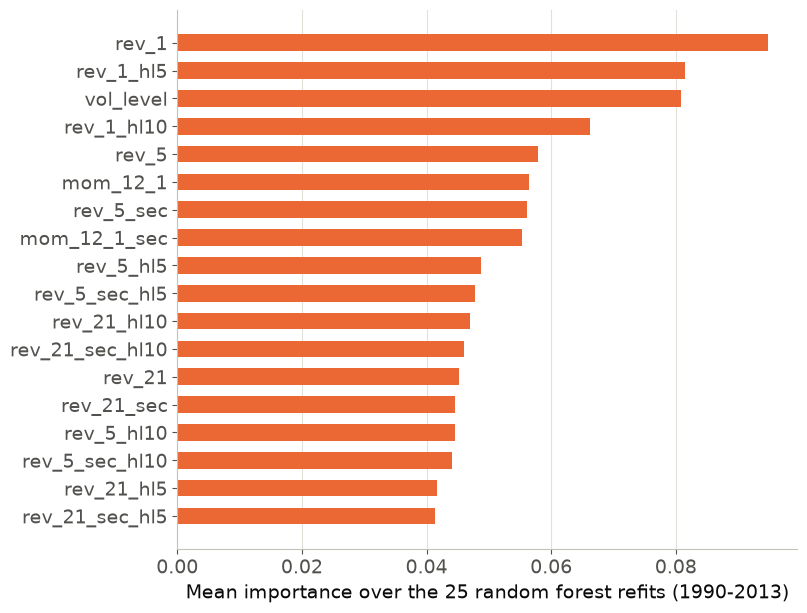

In [22]:
report3.fig_full_cumulative()
report3.fig_model_internals()

## 10. How much was tried

In [23]:
log = pd.read_csv("results/experiment_log.csv")
print("rows in the experiment log:", len(log))
pd.DataFrame({"rows": log.groupby("phase").size()}).rename(index={0: "0: harness checks", 2: "2: development", 3: "3: test evaluation and post-hoc"})

rows in the experiment log: 84


,rows
phase,
0: harness checks,4
2: development,62
3: test evaluation and post-hoc,18
